<img width="1600" height="436" alt="Logo + Title+ Slogan Modified (Updated)" src="https://github.com/user-attachments/assets/e8bda4e2-6039-45f9-ab40-070ea569c98b" />

![Robotics Dojo Banner](https://github.com/user-attachments/assets/e8bda4e2-6039-45f9-ab40-070ea569c98b)

# Waste Management AI Training Notebook

**Purpose:** This notebook is used to train an Object-Detection Model (YOLO26) for use on the Raspberry Pi. 

### Prototype classes
- `organic` → e.g.  **watermelon**
- `plastic` e.g.  **bottle**
- `other` →  e.g. **clothing, metals, etc**

### Pipeline Overview
1. Dataset Curation: Data + Labels
2. train/val/test split
3. Pretrained YOLO → training
4. Validation + error analysis
5. Model Conversions & exports
6. Deployable for the Raspberry Pi


## 0. Imports and project configuration

This cell creates the folders used by the notebook and defines the three classes.

Class IDs must remain consistent:
- `0 = organic`
- `1 = plastic`
- `2 = other`


In [1]:
from pathlib import Path
import random
import shutil
import yaml
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os


# Fixes Hailo's DFC's protobuf issue
os.environ["PROTOCOL_BUFFERS_PYTHON_IMPLEMENTATION"] = "python"


# PROJECT = Path.cwd() / "rdj2026-v2i-yolov8"
PROJECT = Path("rdj2026-v2i-yolov8")
RAW_DIR = PROJECT / "raw"
DATASET_DIR = PROJECT
EXPORT_DIR = PROJECT / "exports"

for p in [RAW_DIR, DATASET_DIR, EXPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

CLASSES = ["metal", "organic", "plastic"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}

SEED = 82
random.seed(SEED)
np.random.seed(SEED)

print("Project:", PROJECT)
print("Classes:", CLASS_TO_ID)


Project: rdj2026-v2i-yolov8
Classes: {'metal': 0, 'organic': 1, 'plastic': 2}


## 1. Dataset Curation

We use a dataset that was prepared by the Robotics Dojo Interns 2026


In [2]:
yaml_path = DATASET_DIR / "data.yaml"

print(yaml_path.read_text())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['metal', 'organic', 'plastic']

roboflow:
  workspace: nikita-kamau
  project: rdj2026
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/nikita-kamau/rdj2026/dataset/2


### Inspect the data before training

Quick sanity check to ensure the dataset is okay to proceed


In [ ]:
# Add Code here

## 2. train/validation/test folders

Ultralytics YOLO expects images and matching label files.

Each label line is:

`class_id x_center y_center width height`

with all coordinates normalized from 0 to 1.


In [ ]:
# Add Code here

### Split the dataset

We create:
- 70% training
- 20% validation
- 10% test

The test set is kept separate and should only be used for the final evaluation.


In [ ]:
# Add code here

# Since the provided dataset already is split, this step is unnecessary

### Check class balance

A model can look good overall while performing badly on one class.

We count labels for each class before training.


In [3]:
# Check Class balance

from collections import Counter

counts = Counter()

for split in ["train", "val", "test"]:
    for label_file in (DATASET_DIR / split / "labels").glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                counts[CLASSES[class_id]] += 1

print("Object counts:")
for name in CLASSES:
    print(f"{name:10s}: {counts[name]}")

Object counts:
metal     : 535
organic   : 919
plastic   : 605


### Visual sanity check

Before training, display a few training images with their bounding boxes.

If the boxes or class IDs are wrong, **stop here and fix the dataset**.


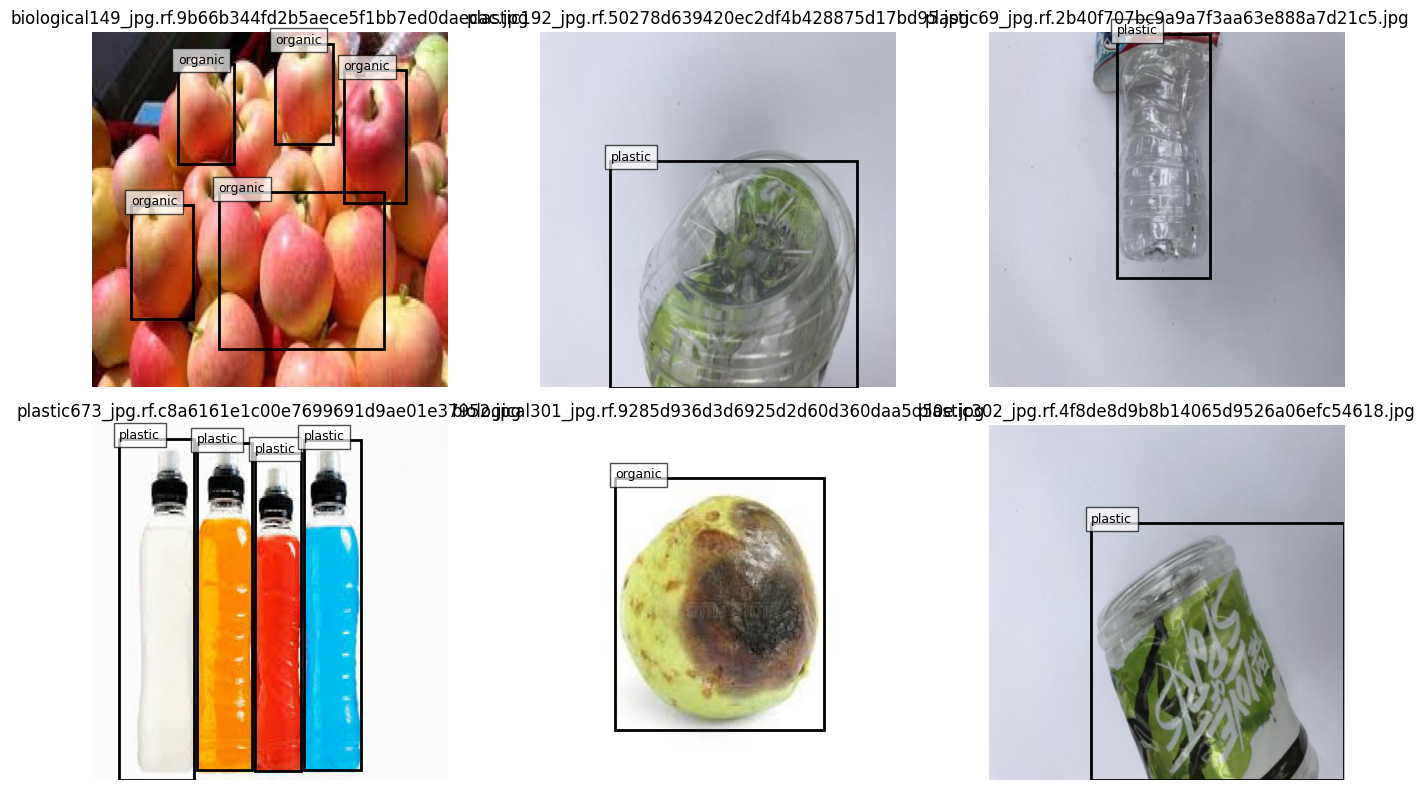

In [4]:
def show_samples(split="train", n=6):
    image_dir = DATASET_DIR / split / "images"
    images = list(image_dir.glob("*"))
    random.Random(SEED).shuffle(images)
    images = images[:n]

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes = axes.flatten()

    for ax, img_path in zip(axes, images):
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(img_path.name)
        ax.axis("off")

        label_path = DATASET_DIR / split / "labels" / f"{img_path.stem}.txt"
        if label_path.exists():
            W, H = img.size
            for line in label_path.read_text().splitlines():
                cls, xc, yc, w, h = map(float, line.split()[:5])
                x1 = (xc - w/2) * W
                y1 = (yc - h/2) * H
                bw = w * W
                bh = h * H
                rect = plt.Rectangle((x1, y1), bw, bh, fill=False, linewidth=2)
                ax.add_patch(rect)
                ax.text(x1, y1, CLASSES[int(cls)], fontsize=9,
                        bbox=dict(facecolor="white", alpha=0.7))

    plt.tight_layout()
    plt.show()

show_samples()


## 3. Train a small pretrained YOLO model

We start with a **small pretrained detection model** so the model can train quickly.

Training Settings:
- `epochs=30`
- batch



### ML Flow Integration

In [6]:
!pip -q install mlflow

In [5]:
!pip -q install jupyter-server-proxy

In [5]:
from ultralytics import YOLO, settings
import time


# Enable MLflow integration
# settings.update({"mlflow": True})

# Define the macro project grouping
experiment_group = "waste_detector_v1"

# Dynamically generate a unique run name
version = "v0.1.0"
arch = "yolo26n"
timestamp = time.strftime("%Y-%m-%d_%H-%M")
run_name = f"{version}_{arch}_{timestamp}-alpha"

model = YOLO(f"{arch}.pt")

print(run_name)

results = model.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=-1,
    patience=10,
    project=str(PROJECT / experiment_group), # ML Flow Experiment Name
    name=run_name, # ML Flow run name
    exist_ok=False,
)

print("Training finished.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
v0.1.0_yolo26n_2026-10-07_07-08-alpha
New https://pypi.org/project/ultralytics/8.4.174 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.156 🚀 Python-3.10.13 torch-2.1.0 CUDA:0 (NVIDIA RTX 4500 Ada Generation, 24117MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=rdj2026-v2i-yolov8/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=

### ML Flow Dashboard

mlflow server --host 0.0.0.0 --port 5000

URL: https://subdomain.trycloudflare.com/proxy/5000/

## 4. Validate the trained model (val set)

Validation answers:

> "How well does the model detect the classes on images it did not train on?"

Pay attention to:
- mAP50
- mAP50-95
- precision
- recall
- per-class performance


In [6]:
# best_model_path = PROJECT / "training_runs" / "production" / "weights" / "best.pt"
best_model_path = Path('/workspace/runs/detect/rdj2026-v2i-yolov8/training_runs/production') / "weights" / "best.pt"
best_model = YOLO(str(best_model_path))

metrics = best_model.val(
    data=str(yaml_path),
    split="val",
    imgsz=640,
)

print("mAP50-95:", metrics.box.map)
print("mAP50:", metrics.box.map50)
print("Per-class mAP50-95:", metrics.box.maps)


Ultralytics 8.4.156 🚀 Python-3.10.13 torch-2.1.0 CUDA:0 (NVIDIA RTX 4500 Ada Generation, 24117MiB)
YOLO26n summary (fused): 120 layers, 2,375,421 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1261.4±682.6 MB/s, size: 33.6 KB)
val: Scanning /workspace/rdj2026-v2i-yolov8/valid/labels.cache... 304 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 304/304 70.8Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 3, len(boxes) = 523. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 11.8it/s 1.6s0.1s
                   all        304        523      0.821      0.739      0.821      0.544
                 metal        101        137      0.885      0.869      0.932      0.663
         

### Test on completely unseen images (test set)

The test set should be treated as the final exam.


In [ ]:
test_metrics = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
)

print("TEST mAP50-95:", test_metrics.box.map)
print("TEST mAP50:", test_metrics.box.map50)
print("TEST per-class mAP50-95:", test_metrics.box.maps)


### Run inference on test images

> **Does the model put the correct box around the correct waste object?**


In [ ]:
test_images = list((DATASET_DIR / "test" / "images").glob("*"))

# print(test_images)

predictions = best_model.predict(
    source=[str(p) for p in test_images[:12]],
    imgsz=640,
    conf=0.25,
    save=True,
    project=str(PROJECT / "predictions"),
    name="test_predictions",
    exist_ok=True,
)

print("Prediction images saved to:", PROJECT / "predictions" / "test_predictions")


## 5. Model Conversions

The important artifact is:

`best.pt`

Also save:
- `data.yaml`
- the dataset
- training results
- this notebook
- a requirements file
- a README describing the experiment

This makes the experiment reproducible on another computer.


In [ ]:
# Copy the best model into a simple export location.
rpi_deployable_model = EXPORT_DIR / "best.pt"
shutil.copy2(best_model_path, rpi_deployable_model)

# Copy data.yaml
shutil.copy2(yaml_path, EXPORT_DIR / "data.yaml")

print("RPi Deployable model:", rpi_deployable_model)


### Convert model to NCNN Format

Ultralytics officially recommends NCNN as the highest-performing option for ARM-based embedded CPUs

https://docs.ultralytics.com/guides/raspberry-pi


In [ ]:
# Load your trained YOLO26n PyTorch model
# model = YOLO("yolo26n.pt")
model = YOLO(best_model_path)

# Export to highly optimized NCNN format
model.export(format="ncnn")

### Convert model to ONNX Format

In [ ]:
# Export to ONNX format
model.export(format="onnx")

### Convert model to HEIF Format

This is for use specifically with the AI HAT+ (Hailo-8L) accelerator

- HEIF: Hailo Executable Format

In [ ]:
# Install Hailo's Dependencies 
# Download Hailo Dataflow Compiler from Hailo's Developer Zone
# https://hailo.ai/developer-zone/software-downloads
!pip -q install hailo_dataflow_compiler-3.34.0-py3-none-linux_x86_64.whl
!pip install --force-reinstall protobuf==3.20.0

In [ ]:
# Export to HEIF format
# (Note: This requires the Hailo Dataflow Compiler toolchain installed)
# model.export(format="hailo")

# Issues:
# 

#### Issues with Hailo Export

export failure 11.5s: /lib/x86_64-linux-gnu/libc.so.6: version `GLIBC_2.34' not found

- The error version GLIBC_2.34 not found means that the Hailo Dataflow Compiler (DFC) or its compiled dependencies were built for a newer Linux operating system (like Ubuntu 22.04 or newer), but you are running them on an older host OS (like Ubuntu 20.04 or Debian 11) that only has an older version of glibc (such as GLIBC 2.31 or 2.33).
- Because glibc is the core C library of the operating system, you cannot safely upgrade it on your current system without breaking the entire OS.

#### Solutions

1. Hailo Model Zoo CLI (Ubuntu Compatible)
2. Hailo SW Suite Docker

## 6. Raspberry Pi Deployment

Robotics Dojo provides a ROS2 Package that utilizes the trained model, with support for both CPU-only and Accelerator-enabled inference:

- Use NCNN for CPU-Only inference
- Use HEIF for Accelerator-enabled inference

More info about the Robotics Dojo ROS2 Package

In [ ]:
# import zipfile

# zip_path = EXPORT_DIR / "rpi_models.zip"


# best_ncnn_model_dir = '/workspace/runs/detect/rdj2026-v2i-yolov8/training_runs/production/weights/best_ncnn_model'
# best_onnx_model = '/workspace/runs/detect/rdj2026-v2i-yolov8/training_runs/production/weights/best.onnx'

# shutil.copy2(best_ncnn_model_dir, EXPORT_DIR)
# shutil.copy2(best_onnx_model, EXPORT_DIR)

# with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:

#     z.write(rpi_deployable_model, rpi_deployable_model.relative_to(PROJECT))
#     z.write(best_ncnn_model_dir, best_ncnn_model_dir.relative_to(PROJECT))
#     z.write(best_onnx_model, best_onnx_model.relative_to(PROJECT))
    


# print("Package created:", zip_path)


# GLHF ;)